# Fake Simulation Demo

This notebook uses `DatasetSimulator` as a virtual simulator. It selects generated samples from existing `data/*.pkl` files, calls the same `simulate()` interface intended for the BNN online loop, and plots S-parameter responses.

In [1]:
from pathlib import Path
import os
import pickle
import sys

import matplotlib.pyplot as plt
import numpy as np
import yaml

NOTEBOOK_DIR = Path.cwd()
REPO_ROOT = NOTEBOOK_DIR if (NOTEBOOK_DIR / "src").exists() else NOTEBOOK_DIR.parent
os.chdir(REPO_ROOT)
if str(REPO_ROOT / "src") not in sys.path:
    sys.path.insert(0, str(REPO_ROOT / "src"))

from simulation import DatasetSimulator, SimulationInput, SimulationError

print(f"Repo root: {REPO_ROOT}")

Repo root: /home/zhanghf/projects/vector


## Case Presets

Change `SELECTED_CASE` and `SAMPLE_INDEX` to run different fake simulations.

In [2]:
CASE_PRESETS = {
    "filter": {
        "config_path": Path("configs/filter_bnn_online_uaw_uaw.yaml"),
        "dataset_path": Path("data/filter_bnn_online_uaw_uaw_dataset.pkl"),
        "variable_order": ["L1", "L2", "L3", "W1", "W2", "W3", "S1", "S2"],
        "ports_to_plot": [(0, 0), (0, 1)],
    },
    "inductor": {
        "config_path": Path("configs/inductor_bnn_online_uaw_uaw.yaml"),
        "dataset_path": Path("data/inductor_bnn_online_uaw_uaw_dataset.pkl"),
        "variable_order": ["Din", "S", "W"],
        "ports_to_plot": [(0, 0), (0, 1)],
    },
    "line": {
        "config_path": Path("configs/line_bnn_online_uaw_uaw.yaml"),
        "dataset_path": Path("data/line_bnn_online_uaw_uaw_dataset.pkl"),
        "variable_order": ["W", "S", "L", "H"],
        "ports_to_plot": [(0, 0), (0, 1), (0, 2), (0, 3)],
    },
}

SELECTED_CASE = "filter"
SAMPLE_INDEX = 0

preset = CASE_PRESETS[SELECTED_CASE]
print(f"Selected case: {SELECTED_CASE}")
preset

Selected case: filter


{'config_path': PosixPath('configs/filter_bnn_online_uaw_uaw.yaml'),
 'dataset_path': PosixPath('data/filter_bnn_online_uaw_uaw_dataset.pkl'),
 'variable_order': ['L1', 'L2', 'L3', 'W1', 'W2', 'W3', 'S1', 'S2'],
 'ports_to_plot': [(0, 0), (0, 1)]}

## Build Simulator And Request

In [3]:
def load_yaml(path):
    with path.open("r") as f:
        return yaml.safe_load(f)


def load_online_dataset(path):
    with path.open("rb") as f:
        payload = pickle.load(f)
    return payload["dataset"] if isinstance(payload, dict) and "dataset" in payload else payload


def freqs_from_config(config):
    freq_cfg = config["data"]["freqs"]
    return np.arange(freq_cfg["min"], freq_cfg["max"], freq_cfg["step"])


def request_from_dataset_sample(case_name, sample, variable_order):
    geo_params = np.asarray(sample["geo_params"], dtype=float)
    if len(geo_params) != len(variable_order):
        raise ValueError(
            f"variable_order has {len(variable_order)} names, but sample has {len(geo_params)} parameters"
        )
    variables = dict(zip(variable_order, geo_params.tolist()))
    return SimulationInput(
        case_id=f"fake_{case_name}_{sample['caseid']}",
        variables=variables,
        variable_order=variable_order,
    )


config = load_yaml(preset["config_path"])
dataset = load_online_dataset(preset["dataset_path"])
sample = dataset[SAMPLE_INDEX]
freqs = freqs_from_config(config)

simulator = DatasetSimulator(
    dataset_path=preset["dataset_path"],
    freqs=freqs,
    port_num=config["target"]["port_num"],
    param_start_idx=config["data"]["start_idx"],
    variable_order=preset["variable_order"],
)
request = request_from_dataset_sample(SELECTED_CASE, sample, preset["variable_order"])

print(f"Dataset size: {len(dataset)}")
print(f"Sample caseid: {sample['caseid']}")
print(f"Variables: {request.variables}")

Dataset size: 1323
Sample caseid: 0
Variables: {'L1': 7.7, 'L2': 8.0, 'L3': 7.8, 'W1': 1.0, 'W2': 0.7, 'W3': 1.0, 'S1': 0.13, 'S2': 0.55}


## Run Fake Simulation

In [4]:
output = simulator.simulate(request)
dataset_item = output.to_dataset_item()

print(f"Output case_id: {output.case_id}")
print(f"geo_params shape: {output.geo_params.shape}")
print(f"freqs shape: {output.freqs.shape}")
print(f"s_params shape: {output.s_params.shape}")
print(f"dataset item keys: {list(dataset_item)}")

Output case_id: fake_filter_0
geo_params shape: (8,)
freqs shape: (401,)
s_params shape: (2, 2, 401)
dataset item keys: ['caseid', 'geo_params', 's_params', 'sampled_indices']


## Plot Results

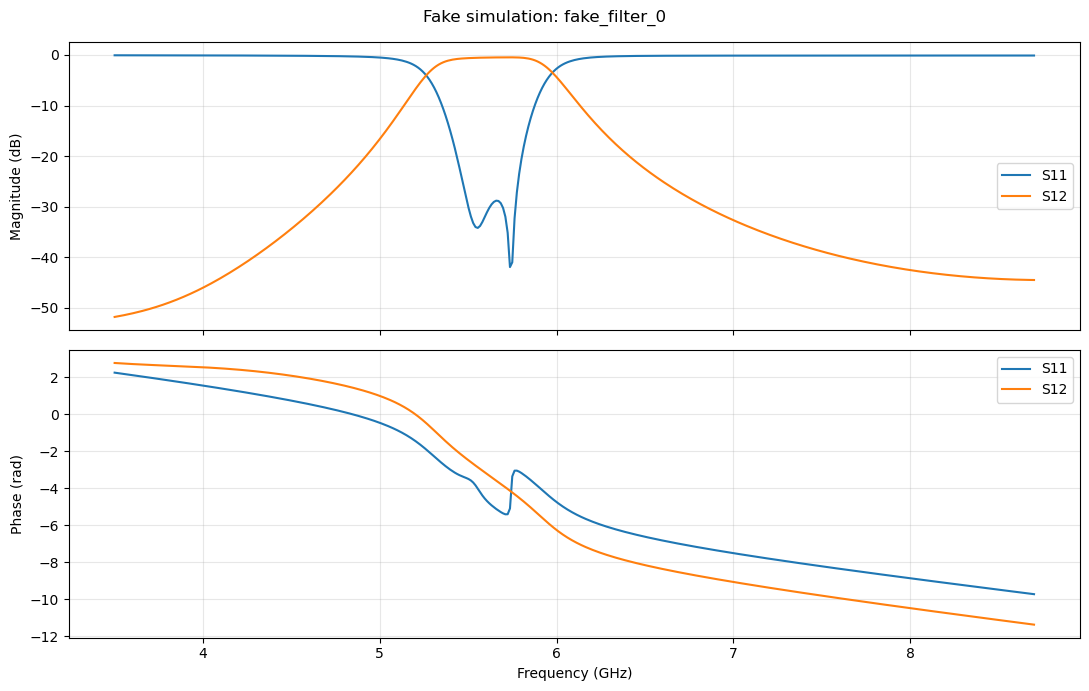

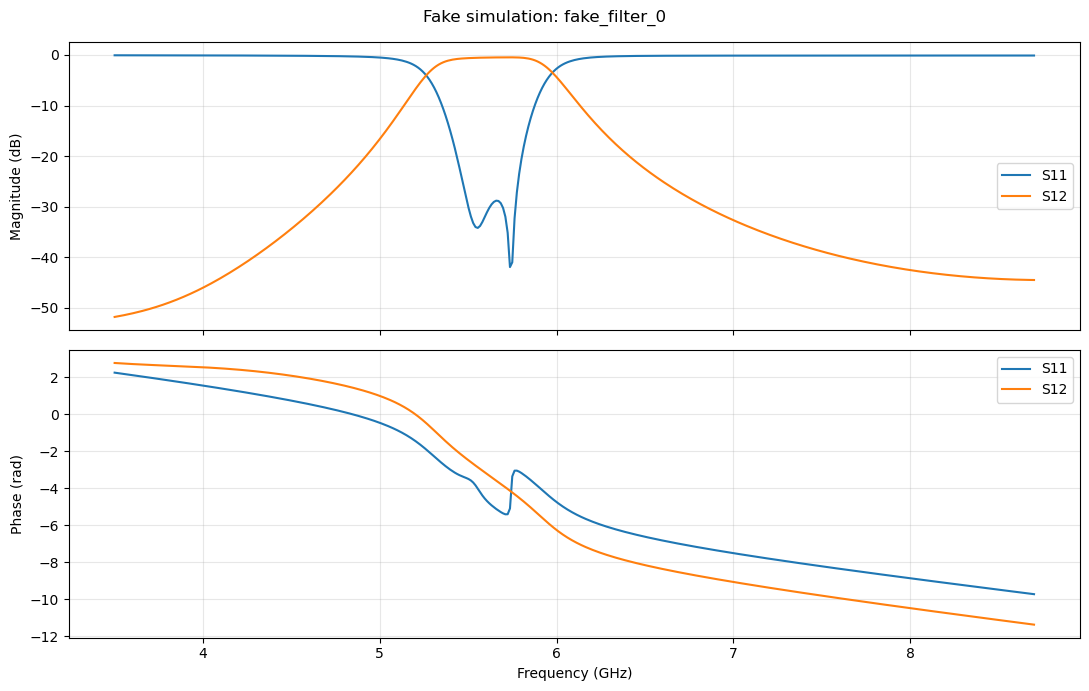

In [5]:
def db20(values):
    return 20 * np.log10(np.maximum(np.abs(values), 1e-12))


def plot_sparams(output, ports_to_plot):
    fig, axes = plt.subplots(2, 1, figsize=(11, 7), sharex=True)
    freq_ghz = output.freqs / 1e9

    for i, j in ports_to_plot:
        label = f"S{i + 1}{j + 1}"
        values = output.s_params[i, j]
        axes[0].plot(freq_ghz, db20(values), label=label)
        axes[1].plot(freq_ghz, np.unwrap(np.angle(values)), label=label)

    axes[0].set_ylabel("Magnitude (dB)")
    axes[0].legend()
    axes[0].grid(True, alpha=0.3)
    axes[1].set_xlabel("Frequency (GHz)")
    axes[1].set_ylabel("Phase (rad)")
    axes[1].legend()
    axes[1].grid(True, alpha=0.3)
    fig.suptitle(f"Fake simulation: {output.case_id}")
    plt.tight_layout()
    return fig


plot_sparams(output, preset["ports_to_plot"])

## Compare Several Samples

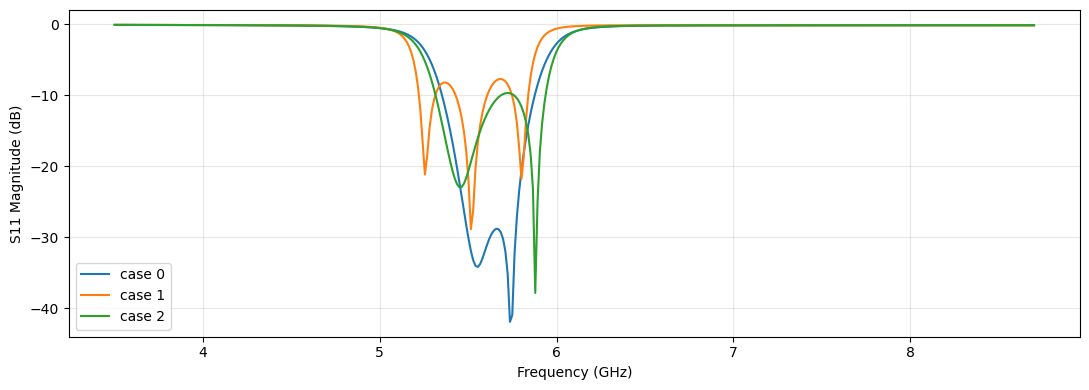

In [6]:
SAMPLE_INDICES = [0, 1, 2]
PORT_TO_COMPARE = preset["ports_to_plot"][0]

fig, ax = plt.subplots(figsize=(11, 4))
for sample_index in SAMPLE_INDICES:
    sample = dataset[sample_index]
    request = request_from_dataset_sample(SELECTED_CASE, sample, preset["variable_order"])
    output = simulator.simulate(request)
    i, j = PORT_TO_COMPARE
    ax.plot(output.freqs / 1e9, db20(output.s_params[i, j]), label=f"case {sample['caseid']}")

ax.set_xlabel("Frequency (GHz)")
ax.set_ylabel(f"S{PORT_TO_COMPARE[0] + 1}{PORT_TO_COMPARE[1] + 1} Magnitude (dB)")
ax.legend()
ax.grid(True, alpha=0.3)
plt.tight_layout()